In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squidpy as sq
import scanpy as sc
import os


from knit.run_test import compute_gram_matrix
from knit.compute_statistic import centre_rows_and_columns

from scipy.sparse.linalg import eigs
from scipy.stats import t, laplace, chi2, norm

In [3]:
fontsize = 12
ms = 5
marker = 'o'
cmap = 'plasma'
marker_list = ['o', 'v', '>' ,'s', '*', 'p',  '^', '<',]
linestyle_list = ['solid', 'dashed', 'dotted', 'dashdot',  (0, (3, 1, 1, 1, 1, 1))]
N_colors = 6
blues = [plt.cm.Blues(i / (N_colors - 1)) for i in range(N_colors)][1:]
capsize = 0
transparency = 1
linewidth = 1.5
alpha_CI = 0.05

# HSIC vs normHSIC

## Level

Figure 1 (S2, S3)

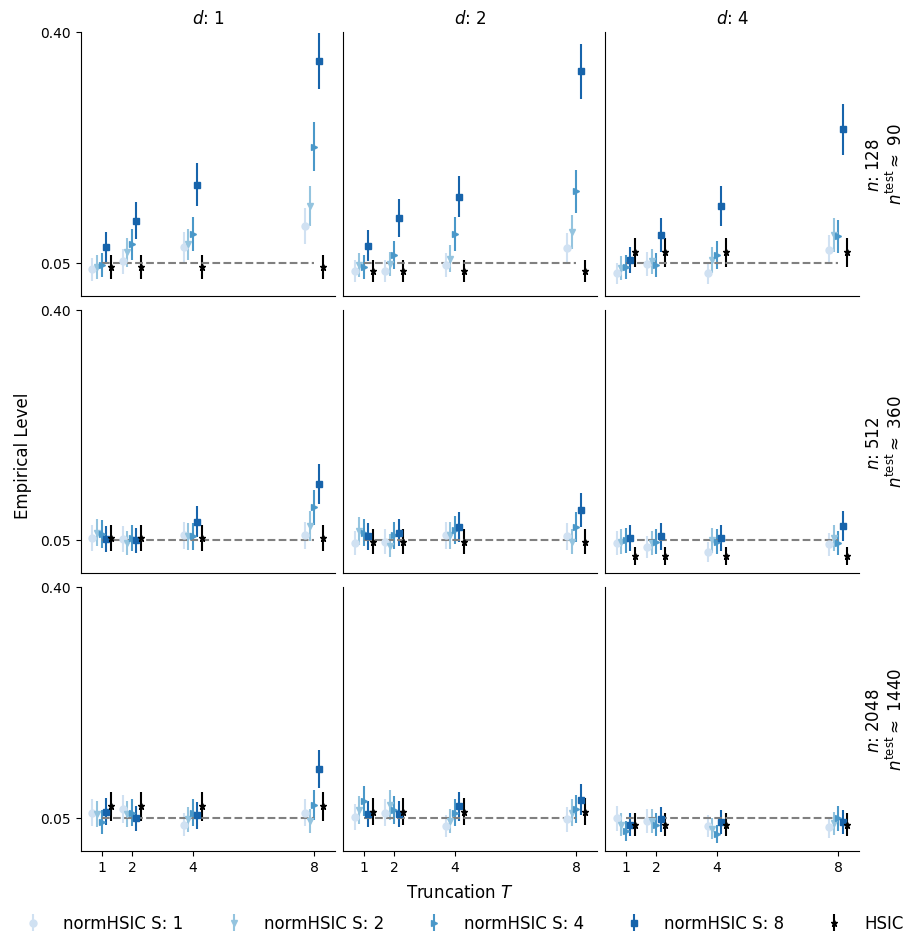

In [6]:
results_directory = 'results/snakemake/output'

# for dist in ['a', 'c','g']:
for dist in ['a']:
    n_list = [128,512, 2048]
    d_list = [1, 2, 4]
    truncation_X_list = [1, 2,4, 8]
    truncation_e_list =  [1, 2, 4, 8]

    nrows = len(n_list)
    ncols = len(d_list)
    fig, axes = plt.subplots(nrows, ncols, figsize = (3*ncols, 3*nrows), sharex=True, sharey=True, layout="constrained")
    offsets = np.linspace(-0.3, 0.3, len(truncation_X_list) + 1)

    # Plot results
    for i in range(nrows):
        n = n_list[i]
        for j in range(ncols):
            d = d_list[j]
            ax = axes[i,j]
            file = f'n_{n}_d_{d}_dist_{dist}_angle_0.csv'

            # add level for normHSIC, each value of S, as a function of values of T
            method = 'normhsic'
            df = pd.read_csv(f'{results_directory}/{method}/{file}')    
            for truncation_X in truncation_X_list:
                k = truncation_X_list.index(truncation_X)
                x = []
                y = []
                yerr = []
                for truncation_e in truncation_e_list:
                    mean = df[(df['truncation_X'] == truncation_X)&(df['truncation_e'] == truncation_e)]['mean'].values[0]
                    rep = df[(df['truncation_X'] == truncation_X)&(df['truncation_e'] == truncation_e)]['rep'].values[0]
                    x.append(truncation_e + offsets[k])
                    y.append(mean)
                    yerr.append((np.sqrt(mean*(1 - mean))/np.sqrt(rep))*norm.ppf(1 - alpha_CI/2))
                label, color, fmt = f'normHSIC S: {truncation_X}', blues[k], marker_list[k]
                ax.errorbar(x, y, yerr, label = label, color = color,  linewidth=linewidth, capsize=capsize, alpha=transparency, fmt = fmt, ms = ms)

            # add level for HSIC
            method = 'hsic'
            df = pd.read_csv(f'{results_directory}/{method}/{file}')  
            k = len(truncation_X_list)
            x = truncation_e_list + offsets[k]
            mean = df['mean'].values[0]
            rep = df['rep'].values[0]
            y = [mean]*len(truncation_e_list)
            yerr = [(np.sqrt(mean*(1 - mean))/np.sqrt(rep))*norm.ppf(1 - alpha_CI/2)]*len(truncation_e_list)
            label, color, fmt = f'HSIC', 'black', marker_list[k]
            ax.errorbar(x, y, yerr, label = label, color = color,  linewidth=linewidth, capsize=capsize, alpha=transparency, fmt = fmt, ms = ms)

            # alpha
            ax.plot(truncation_e_list, [0.05]*len(truncation_e_list), ls = 'dashed', color = 'grey', alpha = transparency)


    # Formatting 
    ylim = .4
    n_test_list = [90, 360, 1440]
    axes[0,0].set(yticks = [0.05, ylim], xticks = truncation_e_list, ylim = (0, ylim))

    for i in range(nrows):
        ax = axes[i,-1]
        ax.set_ylabel(f'$n$: {n_list[i]} \n$  n^{{\\text{{test}}}}  \\approx$ {n_test_list[i]}', fontsize = fontsize)
        ax.yaxis.set_label_position("right")
        for j in range(1, ncols):
            ax = axes[i,j]
            ax.tick_params("y", length = 0)

    for j in range(ncols):
        ax = axes[0,j]
        ax.set_title(f'$d$: {d_list[j]}', fontsize = fontsize)      
        for i in range(nrows - 1):
            ax = axes[i,j]
            ax.tick_params("x", length = 0)

    for i in range(nrows):
        for j in range(ncols):
            ax = axes[i,j]
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

    handles, labels = plt.gca().get_legend_handles_labels()
    fig.legend(handles, labels, ncol = 5, frameon = False, fontsize = fontsize, loc = 'center',  bbox_to_anchor=(0.5, -0.02))
    fig.supxlabel(f'Truncation $T$', fontsize = fontsize)
    fig.supylabel('Empirical Level', fontsize = fontsize) 

    # fig.savefig(f'hsic_comparision_level_dist_{dist}.pdf', bbox_inches='tight')

## Power

Figure 2 (S6, S7)

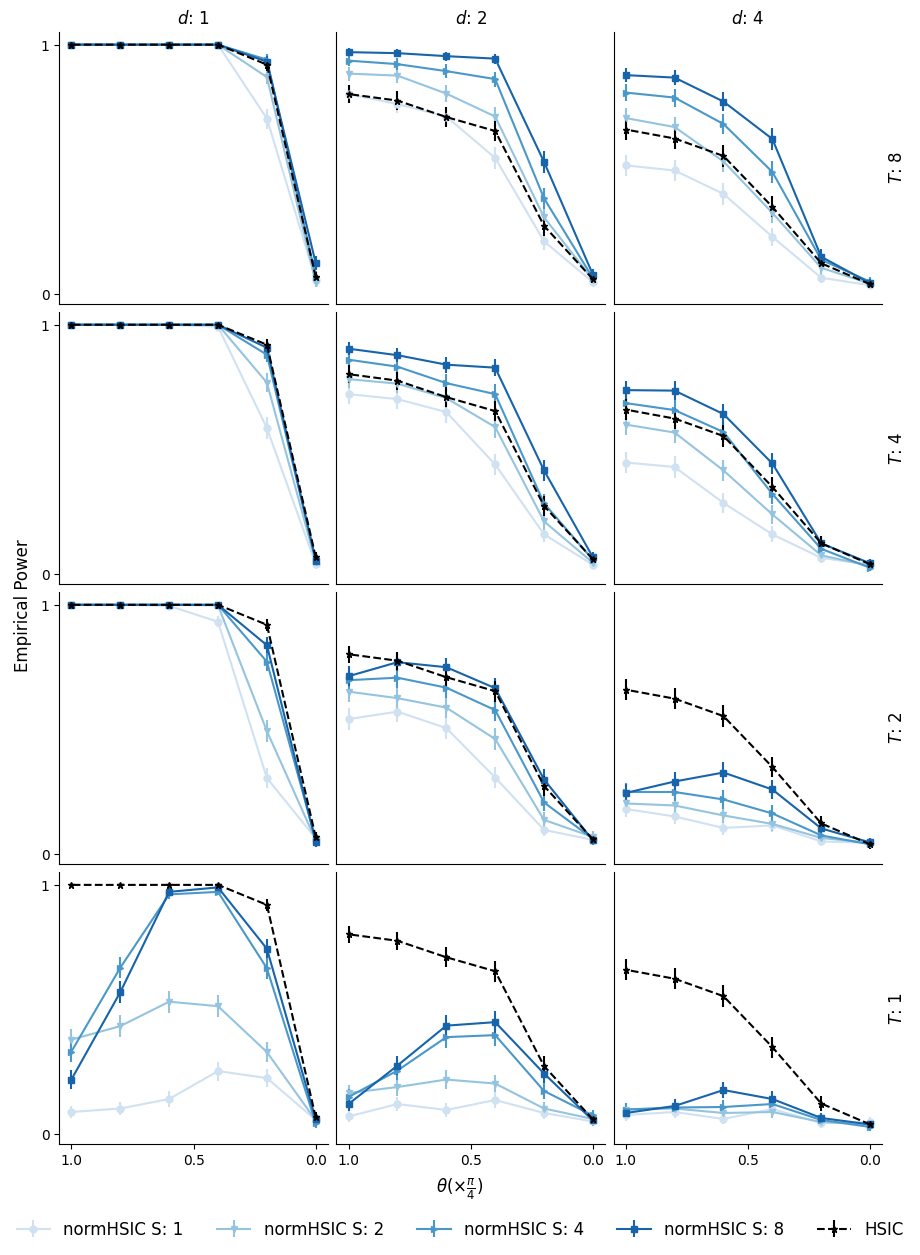

In [7]:
results_directory = 'results/snakemake/output'

# for dist in ['a', 'c', 'g']:
for dist in ['a']:

    n = 2048
    d_list = [1, 2, 4]
    truncation_X_list = [1, 2,4, 8]
    truncation_e_list =  [1, 2, 4, 8]
    truncation_e_list.sort(reverse=True)
    scale_pi_over_four_list = [0, 0.2, 0.4, 0.6, 0.8, 1]

    nrows = len(truncation_e_list)
    ncols = len(d_list)
    fig, axes = plt.subplots(nrows, ncols, figsize = (3*ncols, 3*nrows), sharex=True, sharey=True, layout="constrained")

    # Plot results
    for i in range(nrows):
        truncation_e = truncation_e_list[i]
        for j in range(ncols):
            d = d_list[j]
            ax = axes[i,j]

            # add level for normHSIC, each value of S, as a function of values of T
            method = 'normhsic'
            for truncation_X in truncation_X_list:
                k = truncation_X_list.index(truncation_X)
                x = []
                y = []
                yerr = []
                for scale_pi_over_four in scale_pi_over_four_list:
                    file = f'n_{n}_d_{d}_dist_{dist}_angle_{scale_pi_over_four}.csv'
                    df = pd.read_csv(f'{results_directory}/{method}/{file}')    
                    mean = df[(df['truncation_X'] == truncation_X)&(df['truncation_e'] == truncation_e)]['mean'].values[0]
                    rep = df[(df['truncation_X'] == truncation_X)&(df['truncation_e'] == truncation_e)]['rep'].values[0]
                    x.append(scale_pi_over_four)
                    y.append(mean)
                    yerr.append((np.sqrt(mean*(1 - mean))/np.sqrt(rep))*norm.ppf(1 - alpha_CI/2))
                label, color, fmt, ls = f'normHSIC S: {truncation_X}', blues[k], marker_list[k], linestyle_list[0]
                ax.errorbar(x, y, yerr, label = label, color = color,  linewidth=linewidth, capsize=capsize, alpha=transparency, fmt = fmt, ms = ms, ls = ls)

            # add level for HSIC
            method = 'hsic'
            k = len(truncation_X_list)
            x = []
            y = []
            yerr = []
            for scale_pi_over_four in scale_pi_over_four_list:
                file = f'n_{n}_d_{d}_dist_{dist}_angle_{scale_pi_over_four}.csv'
                df = pd.read_csv(f'{results_directory}/{method}/{file}')    
                mean = df['mean'].values[0]
                rep = df['rep'].values[0]
                x.append(scale_pi_over_four)
                y.append(mean)
                yerr.append((np.sqrt(mean*(1 - mean))/np.sqrt(rep))*norm.ppf(1 - alpha_CI/2))
            label, color, fmt, ls = f'HSIC', 'black', marker_list[k], linestyle_list[1]
            ax.errorbar(x, y, yerr, label = label, color = color,  linewidth=linewidth, capsize=capsize, alpha=transparency, fmt = fmt, ms = ms , ls = ls)


    # Formatting 
    ax = axes[0,0]
    ax.set(yticks = [0, 1], xticks = [0, .5, 1])
    ax.invert_xaxis()

    for i in range(nrows):
        ax = axes[i,-1]
        ax.set_ylabel(f'$T$: {truncation_e_list[i]}', fontsize = fontsize)
        ax.yaxis.set_label_position("right")
        for j in range(1, ncols):
            ax = axes[i,j]
            ax.tick_params("y", length = 0)

    for j in range(ncols):
        ax = axes[0,j]
        ax.set_title(f'$d$: {d_list[j]}', fontsize = fontsize)      
        for i in range(nrows - 1):
            ax = axes[i,j]
            ax.tick_params("x", length = 0)

    for i in range(nrows):
        for j in range(ncols):
            ax = axes[i,j]
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

    handles, labels = plt.gca().get_legend_handles_labels()
    fig.legend(handles, labels, ncol = 5, frameon = False, fontsize = fontsize, loc = 'center',  bbox_to_anchor=(0.5, -0.02))
    fig.supxlabel('$\\theta (\\times \\frac{\\pi}{4})$ ', fontsize = fontsize)
    fig.supylabel('Empirical Power', fontsize = fontsize) 

    # fig.savefig(f'hsic_comparision_power_dist_{dist}.pdf', bbox_inches='tight')

# Varying size of the train set for normHSIC

## Level

Figure S5

Text(0.02, 0.5, 'Empirical Level')

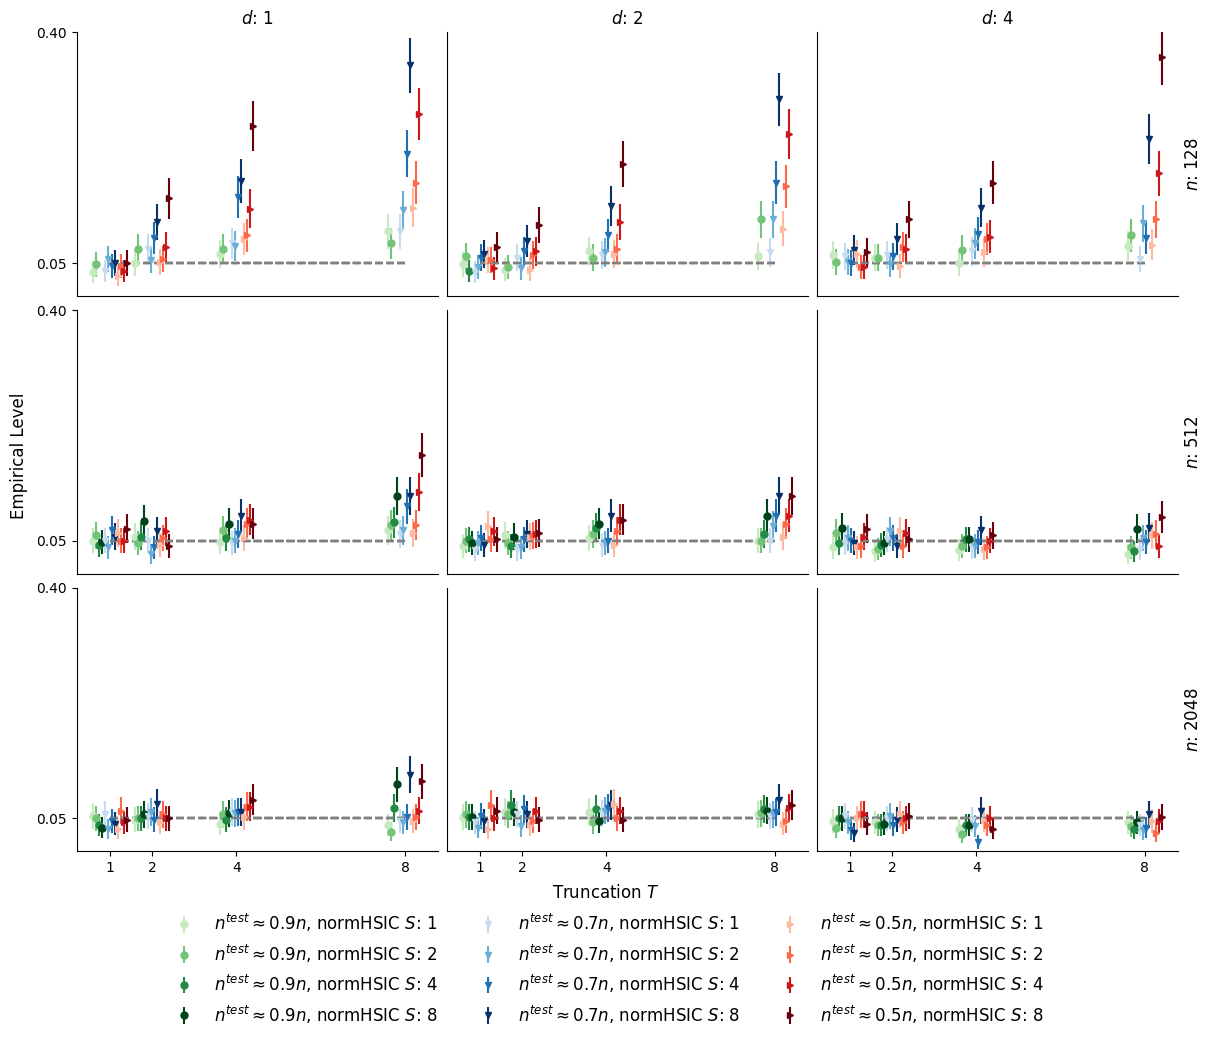

In [4]:
path = 'results/snakemake_proportion_train/output'
dist = 'a'
method = 'normhsic'
scale_pi_over_four = 0

proportion_train_list  = [0.1, 0.3, 0.5]
truncation_X_list = [1, 2, 4, 8]
truncation_e_list = [1, 2, 4, 8]
n_list = [128, 512, 2048]
d_list = [1, 2, 4]

N_colors = len(truncation_X_list) + 1
blues2 = [plt.cm.Blues(i / (N_colors - 1)) for i in range(N_colors)][1:]
reds = [plt.cm.Reds(i / (N_colors - 1)) for i in range(N_colors)][1:]
purples = [plt.cm.Purples(i / (N_colors - 1)) for i in range(N_colors)][1:]
greens = [plt.cm.Greens(i / (N_colors - 1)) for i in range(N_colors)][1:]
colors = [greens, blues2, reds, purples]

ncols = len(d_list)
nrows = len(n_list)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(4*ncols, 3*nrows), sharex=True, sharey=True, layout='constrained')
offsets = np.linspace(-.4, .4, len(proportion_train_list)*len(truncation_X_list))

# Plot Results
for i in range(nrows):
    n = n_list[i]
    for j in range(ncols):
        d = d_list[j]
        ax = axes[i,j]
        for proportion_train in proportion_train_list:
            k = proportion_train_list.index(proportion_train)
            for truncation_X in truncation_X_list:
                l = truncation_X_list.index(truncation_X)
                x = []
                y = []
                yerr = []
                for truncation_e in truncation_e_list:
                    file = f'n_{n}_d_{d}_dist_{dist}_angle_{scale_pi_over_four}_proptrain_{proportion_train}_S_{truncation_X}_T_{truncation_e}.csv'
                    if os.path.exists(f'{path}/{method}/{file}'):
                        df = pd.read_csv(f'{path}/{method}/{file}')
                        mean = df['mean'].values[0]
                        rep = df['rep'].values[0]
                        x.append(truncation_e + offsets[k*len(truncation_X_list) + l])
                        y.append(mean)
                        yerr.append((np.sqrt(mean*(1 - mean))/np.sqrt(rep))*norm.ppf(1 - alpha_CI/2))
                label, color, fmt = f'$n^{{test}} \\approx {1 - proportion_train}n$, normHSIC $S$: {truncation_X}', colors[k][l], marker_list[k]
                ax.errorbar(x, y, yerr, label = label, color = color,  linewidth=linewidth, capsize=capsize, alpha=transparency, fmt = fmt, ms = ms)
                ax.plot(truncation_e_list, 0.05*np.ones(len(truncation_e_list)), linewidth = linewidth, color = 'grey', ls = '--')



# Formatting
ylim = .4
axes[0,0].set(yticks = [0.05, ylim], xticks = truncation_e_list, ylim = (0, ylim))

for i in range(nrows):
    ax = axes[i,-1]
    ax.set_ylabel(f'$n$: {n_list[i]}', fontsize = fontsize)
    ax.yaxis.set_label_position("right")
    for j in range(1, ncols):
        ax = axes[i,j]
        ax.tick_params("y", length = 0)
    for j in range(ncols):
        ax = axes[i,j]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

for j in range(ncols):
    ax = axes[0,j]
    ax.set_title(f'$d$: {d_list[j]}', fontsize = fontsize)      
    for i in range(nrows - 1):
        ax = axes[i,j]
        ax.tick_params("x", length = 0)


handles, labels = plt.gca().get_legend_handles_labels()
fig.legend(handles, labels, ncol = len(proportion_train_list), frameon = False, fontsize = fontsize, loc = 'center',  bbox_to_anchor=(0.5, -0.07))
fig.supxlabel(f'Truncation $T$', fontsize = fontsize)
fig.supylabel('Empirical Level', fontsize = fontsize) 
# fig.savefig('proportion_train_level.pdf', bbox_inches='tight')


## Power

Figure S8

In [ ]:
path = 'results/snakemake_proportion_train/output'
dist = 'a'
method = 'normhsic'
n = 2048
scale_pi_over_four = 0

proportion_train_list  = [0.1, 0.3, 0.5]
truncation_X_list = [1, 2, 4, 8]
truncation_e_list = [1, 2, 4, 8]
d_list = [1, 2, 4]
scale_pi_over_four_list = [0, 0.2, 0.4, 0.6, 0.8, 1]

N_colors = len(truncation_X_list) + 1
blues2 = [plt.cm.Blues(i / (N_colors - 1)) for i in range(N_colors)][1:]
reds = [plt.cm.Reds(i / (N_colors - 1)) for i in range(N_colors)][1:]
purples = [plt.cm.Purples(i / (N_colors - 1)) for i in range(N_colors)][1:]
greens = [plt.cm.Greens(i / (N_colors - 1)) for i in range(N_colors)][1:]
colors = [greens, blues2, reds, purples]

ncols = len(d_list)
nrows = len(truncation_e_list)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3*ncols, 3*nrows), sharex=True, sharey=True, layout='constrained')
offsets = np.linspace(-.4, .4, len(proportion_train_list)*len(truncation_X_list))

# Plot Results
for i in range(nrows):
    truncation_e = truncation_e_list[i]
    for j in range(ncols):
        d = d_list[j]
        ax = axes[i,j]
        for proportion_train in proportion_train_list:
            k = proportion_train_list.index(proportion_train)
            for truncation_X in truncation_X_list:
                l = truncation_X_list.index(truncation_X)
                x = []
                y = []
                yerr = []
                for scale_pi_over_four in scale_pi_over_four_list:
                    file = f'n_{n}_d_{d}_dist_{dist}_angle_{scale_pi_over_four}_proptrain_{proportion_train}_S_{truncation_X}_T_{truncation_e}.csv'
                    if os.path.exists(f'{path}/{method}/{file}'):
                        df = pd.read_csv(f'{path}/{method}/{file}')
                        mean = df['mean'].values[0]
                        rep = df['rep'].values[0]
                        x.append(scale_pi_over_four)
                        y.append(mean)
                        yerr.append((np.sqrt(mean*(1 - mean))/np.sqrt(rep))*norm.ppf(1 - alpha_CI/2))
            
                label, color, fmt, ls = f'$n^{{test}} \\approx {1 - proportion_train}n$, normHSIC $S$: {truncation_X}', colors[l][k], marker_list[l], linestyle_list[k]
                ax.errorbar(x, y, yerr, label = label, color = color,  linewidth=linewidth, capsize=capsize, alpha=transparency, fmt = fmt, ms = ms, ls = ls)

# Formating
ax = axes[0,0]
ax.set(yticks = [0, 1], xticks = [0, .5, 1])
ax.invert_xaxis()

for i in range(nrows):
    ax = axes[i,-1]
    ax.set_ylabel(f'$T$: {truncation_e_list[i]}', fontsize = fontsize)
    ax.yaxis.set_label_position("right")
    for j in range(1, ncols):
        ax = axes[i,j]
        ax.tick_params("y", length = 0)
    for j in range(ncols):
        ax = axes[i,j]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

for j in range(ncols):
    ax = axes[0,j]
    ax.set_title(f'$d$: {d_list[j]}', fontsize = fontsize)      
    for i in range(nrows - 1):
        ax = axes[i,j]
        ax.tick_params("x", length = 0)


handles, labels = plt.gca().get_legend_handles_labels()
fig.legend(handles, labels, ncol = len(proportion_train_list), frameon = False, fontsize = fontsize, loc = 'center',  bbox_to_anchor=(0.5, -0.07))
fig.supxlabel('$\\theta (\\times \\frac{\\pi}{4})$ ', fontsize = fontsize)
fig.supylabel('Empirical Level', fontsize = fontsize) 

# fig.savefig('proportion_train_power.pdf', bbox_inches='tight')
